# Apply Simple Hill Climbing to a Maze Problem

This notebook demonstrates how hill climbing local search behaves applies to the L-Maze problem.

## Setup

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("L_maze.txt", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Local_Search/")
download("maze_helper.py", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Local_Search/")

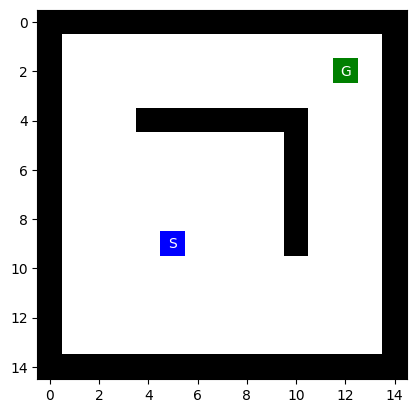

In [2]:
import numpy as np
import maze_helper as mh

f = open("L_maze.txt", "r")

maze_str = f.read()
maze = mh.parse_maze(maze_str)

mh.show_maze(maze)

## Search Helper

We need to define an expand function that will produce the neighbors for local search.

In [3]:
DIR2POS = {
    'N' : (-1, 0),
    'E' : ( 0, 1),
    'S' : ( 1, 0),
    'W' : ( 0,-1)
}

ORDER = None
RANDOMIZATION = None
DIRS = None 

# The order matters if RANDOMIZATION = False
# Note that: DFS works takes elements from the frontier in reverse order!
def set_order(order = "NESW", random = False, verbose = True):
    global RANDOMIZATION, DIR2POS, ORDER, DIRS
    
    RANDOMIZATION = random
    ORDER = [pos for pos in order]
    DIRS = [DIR2POS[dir] for dir in ORDER]
    
    if verbose:
        if RANDOMIZATION:
            print("Directions are checked at every step in random order.")
        else:
            print(f"Directions are checked in the order {ORDER}")
        
set_order("NESW", verbose = True)

Directions are checked in the order ['N', 'E', 'S', 'W']


In [4]:
def expand(maze, pos):
    """find available directions as a list of lists with elements [dir, (pos)]."""
    global RANDOMIZATION, DIRS, ORDER
       
    available = [[dir, pos] for dir, pos in zip(ORDER, np.add(pos, DIRS)) if mh.look(maze, pos) != "X"]
    if RANDOMIZATION: np.random.shuffle(available)
        
    return available

# Hill Climbing

We use Manhattan distance to the goal as the objective function (minimization).

In [5]:
# Manhattan distance h(n)
def manhattan(pos1, pos2):
    """returns the Manhattan distance between two positions"""
    return(np.sum(np.abs(np.subtract(pos1, pos2))))
    
print(manhattan([0,0], [1,1]))

2


In [6]:
def local_search(maze, vis = False, animation = False, verbose = False):
    if animation:
        maze_anim = []
    else:
        maze_anim = None
    
    # Local search starts here
    start_pos = mh.find_pos(maze, "S")
    goal_pos = mh.find_pos(maze, "G")

    current = start_pos
    current_obj = manhattan(current, goal_pos)

    while True:
        # find best neighbor
        neighbors = [n[1] for n in expand(maze, current)]
        obj = [manhattan(n, goal_pos) for n in neighbors]
        best_obj = min(obj)
        best_neighbor = neighbors[obj.index(best_obj)]

        if verbose:
            print("Current state:", current, "with obj", current_obj)
            print("Evaluating neighbors:\t", neighbors)
            print("Obj:\t\t\t", obj)


        # move there if it is an improvement or stop
        if best_obj < current_obj:
            current = best_neighbor
            current_obj = best_obj
            if verbose:
                print("Moving to:", current, "\n")
        else:
            if verbose:
                print("No better state in the neighborhood! Stopping.\n")
            break

        if animation:
            maze2 = maze.copy()
            maze2[current[0], current[1]] = "P"
            maze_anim.append(maze2)


    return { "solution" : current, "path" : None, "reached" : None, "maze_anim" : maze_anim }

## Run the Algorithm

In [7]:
%time result = local_search(maze, animation = True, verbose = True)
result["solution"]

mh.animate_maze(result)

Current state: (np.int64(9), np.int64(5)) with obj 14
Evaluating neighbors:	 [array([8, 5]), array([9, 6]), array([10,  5]), array([9, 4])]
Obj:			 [np.int64(13), np.int64(13), np.int64(15), np.int64(15)]
Moving to: [8 5] 

Current state: [8 5] with obj 13
Evaluating neighbors:	 [array([7, 5]), array([8, 6]), array([9, 5]), array([8, 4])]
Obj:			 [np.int64(12), np.int64(12), np.int64(14), np.int64(14)]
Moving to: [7 5] 

Current state: [7 5] with obj 12
Evaluating neighbors:	 [array([6, 5]), array([7, 6]), array([8, 5]), array([7, 4])]
Obj:			 [np.int64(11), np.int64(11), np.int64(13), np.int64(13)]
Moving to: [6 5] 

Current state: [6 5] with obj 11
Evaluating neighbors:	 [array([5, 5]), array([6, 6]), array([7, 5]), array([6, 4])]
Obj:			 [np.int64(10), np.int64(10), np.int64(12), np.int64(12)]
Moving to: [5 5] 

Current state: [5 5] with obj 10
Evaluating neighbors:	 [array([5, 6]), array([6, 5]), array([5, 4])]
Obj:			 [np.int64(9), np.int64(11), np.int64(11)]
Moving to: [5 6] 

Cu

**Note:** Simple hill climbing is greedy. It gets stuck in local optima!

## Nhận xét kết quả (Bài 1)

- **Vị trí xuất phát:** S = (9, 5); **đích:** G = (2, 12), khoảng cách Manhattan ban đầu h = 7 + 7 = 14.
- **Kết quả:** thuật toán dừng tại ô `result["solution"]` (xem ô lệnh phía trên), cách G còn h = 6, tức là **chưa tới đích**.
- **Vì sao dừng?** Hill Climbing chỉ nhìn các ô lân cận. Khi đi lên/sang phải thì h giảm, nhưng đến sát bức tường dọc thì mọi ô lân cận hợp lệ đều có h **bằng hoặc lớn hơn** ô hiện tại, nên không còn bước cải thiện và thuật toán dừng. Đây là **cực trị cục bộ (local optimum)**: muốn vòng qua tường phải đi tạm xa G (tăng h), điều mà Hill Climbing không bao giờ làm.

## Thử thay đổi thứ tự xét hướng và ngẫu nhiên hóa

Hàm mục tiêu là Manhattan nên thứ tự xét chỉ ảnh hưởng khi có nhiều láng giềng cùng giá trị tốt nhất.

In [8]:
import numpy as np
import matplotlib.pyplot as plt

def run_once(order="NESW", random=False, seed=None):
    if seed is not None:
        np.random.seed(seed)
    set_order(order, random=random, verbose=False)
    return local_search(maze)["solution"]

goal = mh.find_pos(maze, "G")
print("Thứ tự cố định:")
for order in ["NESW", "ESWN", "SWNE", "WNES"]:
    sol = run_once(order)
    print(f"  {order}: dừng tại {tuple(int(v) for v in sol)}, h = {manhattan(sol, goal)}")

print("Thứ tự ngẫu nhiên, 50 lần chạy:")
finals = [tuple(int(v) for v in run_once("NESW", random=True, seed=s)) for s in range(50)]
for pos in sorted(set(finals)):
    print(f"  {pos}: {finals.count(pos)} lần, h = {manhattan(pos, goal)}")
print("Số lần tới đích:", sum(1 for p in finals if p == tuple(int(v) for v in goal)))

set_order("NESW", random=False, verbose=False)  # khôi phục cấu hình mặc định

Thứ tự cố định:
  NESW: dừng tại (5, 9), h = 6
  ESWN: dừng tại (5, 9), h = 6
  SWNE: dừng tại (5, 9), h = 6
  WNES: dừng tại (5, 9), h = 6
Thứ tự ngẫu nhiên, 50 lần chạy:
  (5, 9): 50 lần, h = 6
Số lần tới đích: 0


**Nhận xét:** dù đổi thứ tự hay ngẫu nhiên hóa, thuật toán vẫn dừng ở cùng một vùng cực trị cục bộ trước bức tường. Nguyên nhân là bẫy này nằm ở **hình dạng hàm mục tiêu** (tường chắn giữa S và G), không phụ thuộc cách phá hòa. Muốn thoát cần Random Restart hoặc Simulated Annealing.

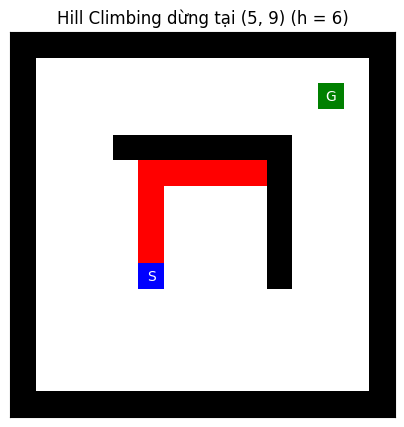

In [9]:
# Lưu hình đường đi của Hill Climbing trên mê cung
def trace_path(maze):
    cur = mh.find_pos(maze, "S")
    goal = mh.find_pos(maze, "G")
    path = [tuple(int(v) for v in cur)]
    while True:
        nb_ = [n[1] for n in expand(maze, cur)]
        obj = [manhattan(n, goal) for n in nb_]
        if min(obj) < manhattan(cur, goal):
            cur = nb_[obj.index(min(obj))]
            path.append(tuple(int(v) for v in cur))
        else:
            return path

path = trace_path(maze)
grid = mh.maze_to_matrix(maze).copy()
for r, c in path[1:]:
    grid[r, c] = 4
from matplotlib import colors
cmap = colors.ListedColormap(["white", "black", "blue", "green", "red", "gray", "orange"])
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(grid, cmap=cmap, norm=colors.BoundaryNorm(range(8), 7))
s, g = mh.find_pos(maze, "S"), mh.find_pos(maze, "G")
ax.text(s[1], s[0], "S", color="white", ha="center", va="center")
ax.text(g[1], g[0], "G", color="white", ha="center", va="center")
ax.set_title(f"Hill Climbing dừng tại {path[-1]} (h = {manhattan(path[-1], goal)})")
ax.set_xticks([]); ax.set_yticks([])
plt.savefig("hinh_maze_hill_climbing.png", dpi=150, bbox_inches="tight")
plt.show()